In [27]:
print("LYMPHIX Python/Jupyter environment is working!")

LYMPHIX Python/Jupyter environment is working!


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible results
np.random.seed(42)

# ---------------------------------------
# Simulation settings
# ---------------------------------------
sampling_rate = 1          # samples per second
duration_minutes = 30
duration_seconds = duration_minutes * 60

time_s = np.arange(duration_seconds)

# ---------------------------------------
# Normal personal baseline
# ---------------------------------------
baseline_load = 500.0      # grams

# Normal sensor variation
noise = np.random.normal(
    loc=0,
    scale=3,
    size=len(time_s)
)

load_g = baseline_load + noise

# ---------------------------------------
# Temporary disturbance
# 5 to 6 minutes
# ---------------------------------------
temporary_event = (
    (time_s >= 300) &
    (time_s < 360)
)

load_g[temporary_event] += np.random.normal(
    loc=0,
    scale=15,
    size=temporary_event.sum()
)

# ---------------------------------------
# Persistent gradual change
# Starts at 15 minutes
# ---------------------------------------
persistent_event = time_s >= 900

elapsed = time_s[persistent_event] - 900

gradual_change = (
    30 * elapsed / (duration_seconds - 900)
)

load_g[persistent_event] += gradual_change

# Persistent offset
load_g[persistent_event] += 20

# ---------------------------------------
# Simulated HX711 raw value
# ---------------------------------------
raw_zero = 842000
conversion_factor = 210

raw = (
    raw_zero
    + load_g * conversion_factor
    + np.random.normal(0, 150, len(time_s))
)

raw = raw.astype(int)

# ---------------------------------------
# Create DataFrame
# ---------------------------------------
df = pd.DataFrame({
    "time_s": time_s,
    "raw": raw,
    "load_g": load_g,
    "load_kg": load_g / 1000
})

# ---------------------------------------
# Save CSV
# ---------------------------------------
output_file = (
    "../../data/loadcell/"
    "LYMPHIX_Loadcell_Simulated.csv"
)

df.to_csv(output_file, index=False)

print("Simulation completed successfully.")
print("Number of samples:", len(df))
print("File saved to:", output_file)

df.head()

Simulation completed successfully.
Number of samples: 1800
File saved to: ../../data/loadcell/LYMPHIX_Loadcell_Simulated.csv


,time_s,raw,load_g,load_kg
0,0,947292,501.490142,0.501490
1,1,947034,499.585207,0.499585
2,2,947527,501.943066,0.501943
3,3,947697,504.569090,0.504569
4,4,947048,499.297540,0.499298


In [29]:
# ==========================================
# LYMPHIX PERSONAL BASELINE
# ==========================================

# Use the first 10 minutes as the normal baseline period
baseline_period = df[df["time_s"] < 600]

# Calculate baseline statistics
baseline_mean = baseline_period["load_g"].mean()
baseline_std = baseline_period["load_g"].std()

print("LYMPHIX PERSONAL BASELINE")
print("-------------------------")
print(f"Baseline mean       : {baseline_mean:.2f} g")
print(f"Baseline std. dev.  : {baseline_std:.2f} g")
print(f"Baseline samples    : {len(baseline_period)}")

LYMPHIX PERSONAL BASELINE
-------------------------
Baseline mean       : 499.84 g
Baseline std. dev.  : 5.20 g
Baseline samples    : 600


In [30]:
# ==========================================
# LYMPHIX DEVIATION FROM BASELINE
# ==========================================

df["deviation_g"] = df["load_g"] - baseline_mean

print(df[
    ["time_s", "load_g", "deviation_g"]
].head(10))

   time_s      load_g  deviation_g
0       0  501.490142     1.651223
1       1  499.585207    -0.253712
2       2  501.943066     2.104146
3       3  504.569090     4.730170
4       4  499.297540    -0.541380
5       5  499.297589    -0.541330
6       6  504.737638     4.898719
7       7  502.302304     2.463385
8       8  498.591577    -1.247343
9       9  501.627680     1.788761


In [31]:
# ==========================================
# LYMPHIX Z-SCORE
# ==========================================

df["z_score"] = (
    df["deviation_g"] / baseline_std
)

print(df[
    ["time_s", "load_g", "deviation_g", "z_score"]
].head(10))

   time_s      load_g  deviation_g   z_score
0       0  501.490142     1.651223  0.317646
1       1  499.585207    -0.253712 -0.048807
2       2  501.943066     2.104146  0.404774
3       3  504.569090     4.730170  0.909942
4       4  499.297540    -0.541380 -0.104145
5       5  499.297589    -0.541330 -0.104136
6       6  504.737638     4.898719  0.942366
7       7  502.302304     2.463385  0.473881
8       8  498.591577    -1.247343 -0.239951
9       9  501.627680     1.788761  0.344104


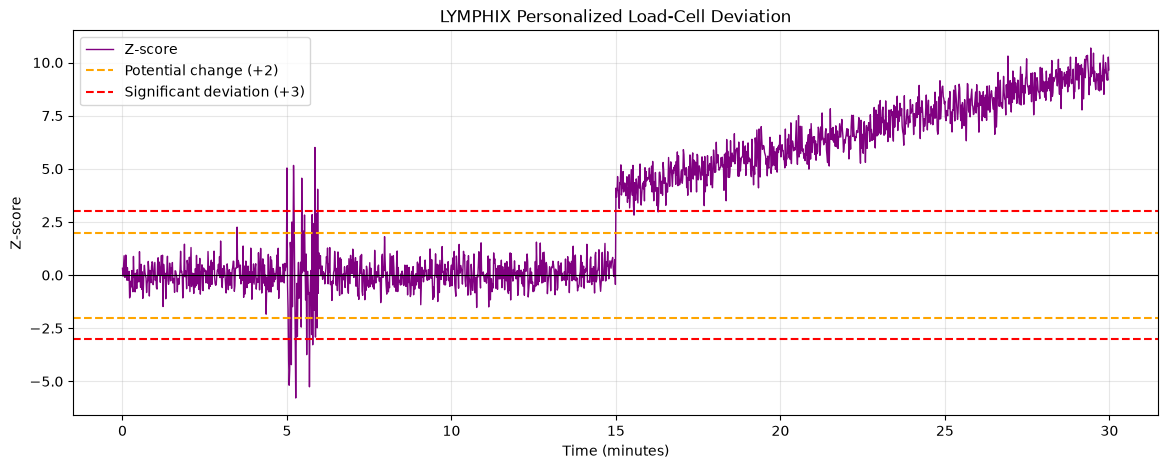

In [32]:
# ==========================================
# LYMPHIX Z-SCORE GRAPH
# ==========================================

plt.figure(figsize=(14, 5))

plt.plot(
    df["time_s"] / 60,
    df["z_score"],
    color="purple",
    linewidth=1,
    label="Z-score"
)

# Prototype thresholds
plt.axhline(
    2,
    color="orange",
    linestyle="--",
    label="Potential change (+2)"
)

plt.axhline(
    -2,
    color="orange",
    linestyle="--"
)

plt.axhline(
    3,
    color="red",
    linestyle="--",
    label="Significant deviation (+3)"
)

plt.axhline(
    -3,
    color="red",
    linestyle="--"
)

plt.axhline(
    0,
    color="black",
    linewidth=0.8
)

plt.xlabel("Time (minutes)")
plt.ylabel("Z-score")

plt.title("LYMPHIX Personalized Load-Cell Deviation")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [33]:
# ==========================================
# LYMPHIX PERSISTENCE DETECTION
# ==========================================

# Prototype abnormality threshold
z_threshold = 2.0

# Mark readings exceeding threshold
df["abnormal"] = (
    df["z_score"].abs() >= z_threshold
)

# Require 30 consecutive abnormal samples
persistence_window = 30

df["persistent_change"] = (
    df["abnormal"]
    .rolling(
        window=persistence_window,
        min_periods=persistence_window
    )
    .sum()
    == persistence_window
)

print(
    "Persistent-warning samples:",
    df["persistent_change"].sum()
)

Persistent-warning samples: 871


In [34]:
# ==========================================
# LYMPHIX WARNING STATE
# ==========================================

df["status"] = "NORMAL"

df.loc[
    df["abnormal"],
    "status"
] = "MONITOR"

df.loc[
    df["persistent_change"],
    "status"
] = "EARLY_WARNING"

print(
    df["status"].value_counts()
)

status
NORMAL           871
EARLY_WARNING    871
MONITOR           58
Name: count, dtype: int64


In [35]:
# ==========================================
# LYMPHIX EARLY-WARNING SCORE
# ==========================================

# Use absolute Z-score
abs_z = df["z_score"].abs()

# Convert Z-score to 0-100 score
df["warning_score"] = (
    abs_z / 4 * 100
).clip(0, 100)

# ------------------------------------------
# Apply persistence
# ------------------------------------------

df.loc[
    df["persistent_change"],
    "warning_score"
] = np.maximum(
    df.loc[df["persistent_change"], "warning_score"],
    70
)

# ------------------------------------------
# Determine final status
# ------------------------------------------

df["final_status"] = "NORMAL"

df.loc[
    (df["warning_score"] >= 40) &
    (df["warning_score"] < 70),
    "final_status"
] = "MONITOR"

df.loc[
    df["warning_score"] >= 70,
    "final_status"
] = "EARLY_WARNING"

print(df["final_status"].value_counts())

final_status
EARLY_WARNING    920
NORMAL           867
MONITOR           13
Name: count, dtype: int64


In [36]:
df[
    [
        "time_s",
        "load_g",
        "z_score",
        "warning_score",
        "final_status"
    ]
].iloc[850:950]

,time_s,load_g,z_score,warning_score,final_status
850,850,498.130578,-0.328633,8.215836,NORMAL
851,851,498.333569,-0.289584,7.239605,NORMAL
852,852,498.087839,-0.336855,8.421382,NORMAL
853,853,503.567050,0.717180,17.929503,NORMAL
854,854,504.261513,0.850774,21.269348,NORMAL
...,...,...,...,...,...
945,945,518.289746,3.549384,88.734600,EARLY_WARNING
946,946,516.956758,3.292957,82.323931,EARLY_WARNING
947,947,519.490942,3.780458,94.511454,EARLY_WARNING
948,948,521.463242,4.159869,100.000000,EARLY_WARNING


In [37]:
# ==========================================
# SAVE LYMPHIX PROCESSED DATA
# ==========================================

processed_file = (
    "../../data/loadcell/"
    "LYMPHIX_Loadcell_Processed.csv"
)

df.to_csv(processed_file, index=False)

print("Processed LYMPHIX dataset saved.")
print(processed_file)

Processed LYMPHIX dataset saved.
../../data/loadcell/LYMPHIX_Loadcell_Processed.csv


In [38]:
# ==========================================
# LYMPHIX MODEL SUMMARY
# ==========================================

print("======================================")
print("        LYMPHIX MODEL SUMMARY")
print("======================================")

print(f"Baseline mean       : {baseline_mean:.2f} g")
print(f"Baseline std. dev.  : {baseline_std:.2f} g")

print(
    f"Maximum Z-score     : "
    f"{df['z_score'].max():.2f}"
)

print(
    f"Maximum warning     : "
    f"{df['warning_score'].max():.2f}"
)

print("\nFINAL STATUS COUNTS")
print(df["final_status"].value_counts())

print("======================================")

        LYMPHIX MODEL SUMMARY
Baseline mean       : 499.84 g
Baseline std. dev.  : 5.20 g
Maximum Z-score     : 10.68
Maximum warning     : 100.00

FINAL STATUS COUNTS
final_status
EARLY_WARNING    920
NORMAL           867
MONITOR           13
Name: count, dtype: int64


In [39]:
======================================
LYMPHIX MULTIMODAL SIMULATION
======================================
Samples: 1800

Saved to:
../../data/loadcell/LYMPHIX_Multimodal_Simulated.csv

SyntaxError: invalid syntax (2114359019.py, line 1)

In [ ]:
# LYMPHIX MULTIMODAL SENSOR SIMULATION
# Load + Pressure + Movement

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible simulation
np.random.seed(42)

# Simulation settings
sampling_rate = 1
duration_minutes = 30
duration_seconds = duration_minutes * 60

time_s = np.arange(duration_seconds)

# ==================================================
# 1. LOAD CELL
# ==================================================

load_baseline = 500.0

load_noise = np.random.normal(
    0,
    3,
    len(time_s)
)

load_g = load_baseline + load_noise

# Temporary disturbance: 5 to 6 minutes
temporary_event = (
    (time_s >= 300) &
    (time_s < 360)
)

load_g[temporary_event] += np.random.normal(
    0,
    15,
    temporary_event.sum()
)

# Persistent change starts at 15 minutes
persistent_event = time_s >= 900

elapsed = time_s[persistent_event] - 900

load_change = (
    30 * elapsed /
    (duration_seconds - 900)
)

load_g[persistent_event] += load_change
load_g[persistent_event] += 20


# ==================================================
# 2. PRESSURE SENSOR
# ==================================================

pressure_baseline = 35.0

pressure_noise = np.random.normal(
    0,
    0.8,
    len(time_s)
)

pressure = pressure_baseline + pressure_noise

# Temporary pressure disturbance
pressure[temporary_event] += np.random.normal(
    0,
    3,
    temporary_event.sum()
)

# Persistent pressure increase
pressure_change = (
    5 * elapsed /
    (duration_seconds - 900)
)

pressure[persistent_event] += pressure_change
pressure[persistent_event] += 3


# ==================================================
# 3. MPU6050 MOVEMENT
# ==================================================

movement_baseline = 1.0

movement_noise = np.random.normal(
    0,
    0.05,
    len(time_s)
)

movement = movement_baseline + movement_noise

# Temporary movement disturbance
movement[temporary_event] += np.random.normal(
    0,
    0.15,
    temporary_event.sum()
)

# Persistent reduction in movement
movement_change = (
    0.30 * elapsed /
    (duration_seconds - 900)
)

movement[persistent_event] -= movement_change
movement[persistent_event] -= 0.15


# ==================================================
# 4. CREATE DATAFRAME
# ==================================================

multi_df = pd.DataFrame({
    "time_s": time_s,
    "load_g": load_g,
    "pressure": pressure,
    "movement": movement
})


# ==================================================
# 5. SAVE DATASET
# ==================================================

multimodal_file = (
    "../../data/loadcell/"
    "LYMPHIX_Multimodal_Simulated.csv"
)

multi_df.to_csv(
    multimodal_file,
    index=False
)


# ==================================================
# 6. DISPLAY RESULT
# ==================================================

print("LYMPHIX MULTIMODAL SIMULATION")
print("--------------------------------")
print("Number of samples:", len(multi_df))
print("Sampling rate:", sampling_rate, "sample/second")
print("Duration:", duration_minutes, "minutes")
print("File saved to:")
print(multimodal_file)

print("\nFirst five samples:")
print(multi_df.head())

LYMPHIX MULTIMODAL SIMULATION
--------------------------------
Number of samples: 1800
Sampling rate: 1 sample/second
Duration: 30 minutes
File saved to:
../../data/loadcell/LYMPHIX_Multimodal_Simulated.csv

First five samples:
   time_s      load_g   pressure  movement
0       0  501.490142  34.892553  1.049779
1       1  499.585207  35.648647  1.085159
2       2  501.943066  35.634791  0.918099
3       3  504.569090  33.601174  0.910681
4       4  499.297540  36.043472  0.968898


In [ ]:
# LYMPHIX MULTIMODAL SENSOR SIMULATION
# Load + Pressure + Movement

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible simulation
np.random.seed(42)

# Simulation settings
sampling_rate = 1
duration_minutes = 30
duration_seconds = duration_minutes * 60

time_s = np.arange(duration_seconds)

# ==================================================
# 1. LOAD CELL
# ==================================================

load_baseline = 500.0

load_noise = np.random.normal(
    0,
    3,
    len(time_s)
)

load_g = load_baseline + load_noise

# Temporary disturbance: 5 to 6 minutes
temporary_event = (
    (time_s >= 300) &
    (time_s < 360)
)

load_g[temporary_event] += np.random.normal(
    0,
    15,
    temporary_event.sum()
)

# Persistent change starts at 15 minutes
persistent_event = time_s >= 900

elapsed = time_s[persistent_event] - 900

load_change = (
    30 * elapsed /
    (duration_seconds - 900)
)

load_g[persistent_event] += load_change
load_g[persistent_event] += 20


# ==================================================
# 2. PRESSURE SENSOR
# ==================================================

pressure_baseline = 35.0

pressure_noise = np.random.normal(
    0,
    0.8,
    len(time_s)
)

pressure = pressure_baseline + pressure_noise

# Temporary pressure disturbance
pressure[temporary_event] += np.random.normal(
    0,
    3,
    temporary_event.sum()
)

# Persistent pressure increase
pressure_change = (
    5 * elapsed /
    (duration_seconds - 900)
)

pressure[persistent_event] += pressure_change
pressure[persistent_event] += 3


# ==================================================
# 3. MPU6050 MOVEMENT
# ==================================================

movement_baseline = 1.0

movement_noise = np.random.normal(
    0,
    0.05,
    len(time_s)
)

movement = movement_baseline + movement_noise

# Temporary movement disturbance
movement[temporary_event] += np.random.normal(
    0,
    0.15,
    temporary_event.sum()
)

# Persistent reduction in movement
movement_change = (
    0.30 * elapsed /
    (duration_seconds - 900)
)

movement[persistent_event] -= movement_change
movement[persistent_event] -= 0.15


# ==================================================
# 4. CREATE DATAFRAME
# ==================================================

multi_df = pd.DataFrame({
    "time_s": time_s,
    "load_g": load_g,
    "pressure": pressure,
    "movement": movement
})


# ==================================================
# 5. SAVE DATASET
# ==================================================

multimodal_file = (
    "../../data/loadcell/"
    "LYMPHIX_Multimodal_Simulated.csv"
)

multi_df.to_csv(
    multimodal_file,
    index=False
)


# ==================================================
# 6. DISPLAY RESULT
# ==================================================

print("LYMPHIX MULTIMODAL SIMULATION")
print("--------------------------------")
print("Number of samples:", len(multi_df))
print("Sampling rate:", sampling_rate, "sample/second")
print("Duration:", duration_minutes, "minutes")
print("File saved to:")
print(multimodal_file)

print("\nFirst five samples:")
print(multi_df.head())

LYMPHIX MULTIMODAL SIMULATION
--------------------------------
Number of samples: 1800
Sampling rate: 1 sample/second
Duration: 30 minutes
File saved to:
../../data/loadcell/LYMPHIX_Multimodal_Simulated.csv

First five samples:
   time_s      load_g   pressure  movement
0       0  501.490142  34.892553  1.049779
1       1  499.585207  35.648647  1.085159
2       2  501.943066  35.634791  0.918099
3       3  504.569090  33.601174  0.910681
4       4  499.297540  36.043472  0.968898


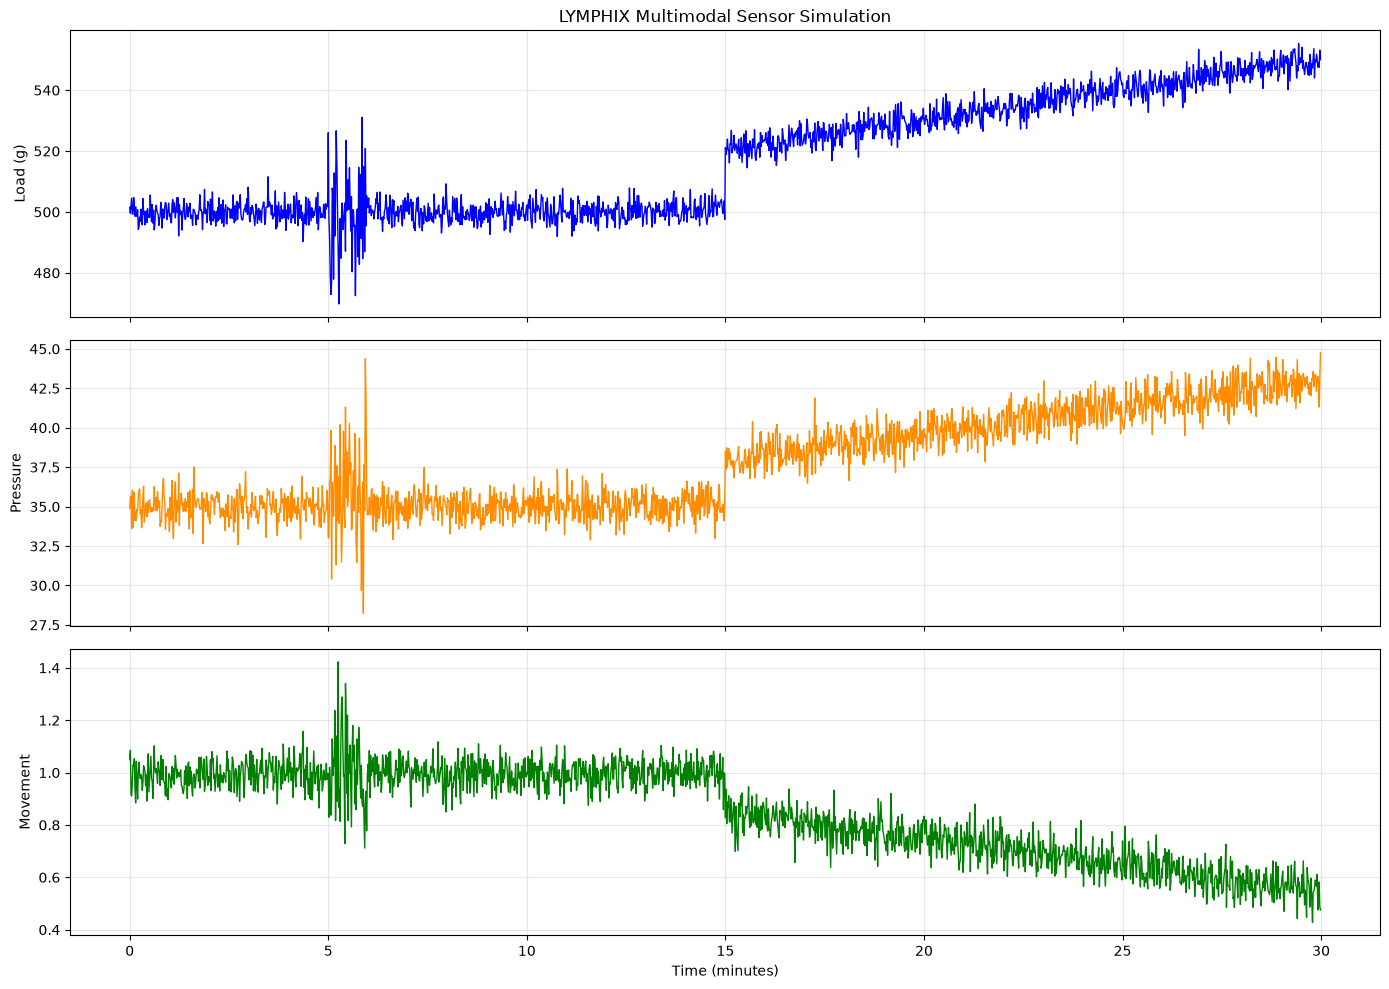

In [ ]:
# LYMPHIX MULTIMODAL SENSOR GRAPH

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 10),
    sharex=True
)

# Load cell
axes[0].plot(
    multi_df["time_s"] / 60,
    multi_df["load_g"],
    color="blue",
    linewidth=1
)

axes[0].set_ylabel("Load (g)")
axes[0].set_title("LYMPHIX Multimodal Sensor Simulation")
axes[0].grid(alpha=0.3)

# Pressure
axes[1].plot(
    multi_df["time_s"] / 60,
    multi_df["pressure"],
    color="darkorange",
    linewidth=1
)

axes[1].set_ylabel("Pressure")
axes[1].grid(alpha=0.3)

# Movement
axes[2].plot(
    multi_df["time_s"] / 60,
    multi_df["movement"],
    color="green",
    linewidth=1
)

axes[2].set_ylabel("Movement")
axes[2].set_xlabel("Time (minutes)")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# LYMPHIX PERSONAL BASELINES

# First 10 minutes = baseline period
baseline_data = multi_df[
    multi_df["time_s"] < 600
]

# Load baseline
load_mean = baseline_data["load_g"].mean()
load_std = baseline_data["load_g"].std()

# Pressure baseline
pressure_mean = baseline_data["pressure"].mean()
pressure_std = baseline_data["pressure"].std()

# Movement baseline
movement_mean = baseline_data["movement"].mean()
movement_std = baseline_data["movement"].std()

print("LYMPHIX PERSONAL BASELINES")
print("---------------------------")

print(
    f"Load      : {load_mean:.2f} ± {load_std:.2f}"
)

print(
    f"Pressure  : {pressure_mean:.2f} ± {pressure_std:.2f}"
)

print(
    f"Movement  : {movement_mean:.2f} ± {movement_std:.2f}"
)

LYMPHIX PERSONAL BASELINES
---------------------------
Load      : 499.84 ± 5.20
Pressure  : 35.07 ± 1.24
Movement  : 0.99 ± 0.07


In [ ]:
# LYMPHIX MULTIMODAL Z-SCORES

# Load-cell Z-score
multi_df["load_z"] = (
    (multi_df["load_g"] - load_mean)
    / load_std
)

# Pressure Z-score
multi_df["pressure_z"] = (
    (multi_df["pressure"] - pressure_mean)
    / pressure_std
)

# Movement Z-score
multi_df["movement_z"] = (
    (multi_df["movement"] - movement_mean)
    / movement_std
)

# Display first 10 samples
print("LYMPHIX MULTIMODAL Z-SCORES")
print("----------------------------")

print(
    multi_df[
        [
            "time_s",
            "load_z",
            "pressure_z",
            "movement_z"
        ]
    ].head(10)
)

LYMPHIX MULTIMODAL Z-SCORES
----------------------------
   time_s    load_z  pressure_z  movement_z
0       0  0.317646   -0.147297    0.814614
1       1 -0.048807    0.463411    1.338603
2       2  0.404774    0.452220   -1.135642
3       3  0.909942   -1.190363   -1.245496
4       4 -0.104145    0.782318   -0.383272
5       5 -0.104136   -1.134767    0.508893
6       6  0.942366    0.606692    0.445308
7       7  0.473881    0.667535    0.869554
8       8 -0.239951   -0.765463   -0.811046
9       9  0.344104   -0.325967   -1.637803


In [ ]:
# LYMPHIX SENSOR FUSION

# Calculate magnitude of each sensor deviation
multi_df["load_component"] = (
    multi_df["load_z"].abs()
)

multi_df["pressure_component"] = (
    multi_df["pressure_z"].abs()
)

multi_df["movement_component"] = (
    multi_df["movement_z"].abs()
)

# Weighted sensor fusion
multi_df["fusion_score"] = (
    0.40 * multi_df["load_component"]
    + 0.35 * multi_df["pressure_component"]
    + 0.25 * multi_df["movement_component"]
)

# Display results
print("LYMPHIX SENSOR-FUSION SCORE")
print("---------------------------")

print(
    multi_df[
        [
            "time_s",
            "load_component",
            "pressure_component",
            "movement_component",
            "fusion_score"
        ]
    ].head(10)
)

LYMPHIX SENSOR-FUSION SCORE
---------------------------
   time_s  load_component  pressure_component  movement_component  \
0       0        0.317646            0.147297            0.814614   
1       1        0.048807            0.463411            1.338603   
2       2        0.404774            0.452220            1.135642   
3       3        0.909942            1.190363            1.245496   
4       4        0.104145            0.782318            0.383272   
5       5        0.104136            1.134767            0.508893   
6       6        0.942366            0.606692            0.445308   
7       7        0.473881            0.667535            0.869554   
8       8        0.239951            0.765463            0.811046   
9       9        0.344104            0.325967            1.637803   

   fusion_score  
0      0.382266  
1      0.516368  
2      0.604097  
3      1.091978  
4      0.411287  
5      0.566046  
6      0.700616  
7      0.640578  
8      0.566654  
9   

In [ ]:
# LYMPHIX MULTIMODAL WARNING SCORE

# Convert fusion score to a 0-100 scale
multi_df["warning_score"] = (
    multi_df["fusion_score"] / 4.0 * 100
).clip(0, 100)

print("LYMPHIX MULTIMODAL WARNING SCORE")
print("--------------------------------")

print(
    multi_df[
        [
            "time_s",
            "fusion_score",
            "warning_score"
        ]
    ].head(10)
)

LYMPHIX MULTIMODAL WARNING SCORE
--------------------------------
   time_s  fusion_score  warning_score
0       0      0.382266       9.556643
1       1      0.516368      12.909188
2       2      0.604097      15.102432
3       3      1.091978      27.299455
4       4      0.411287      10.282187
5       5      0.566046      14.151144
6       6      0.700616      17.515396
7       7      0.640578      16.014456
8       8      0.566654      14.166349
9       9      0.661181      16.529521


In [ ]:
# LYMPHIX MULTIMODAL PERSISTENCE DETECTION

# Prototype abnormality threshold
fusion_threshold = 2.0

# Identify abnormal multimodal readings
multi_df["abnormal"] = (
    multi_df["fusion_score"] >= fusion_threshold
)

# Require 30 consecutive abnormal readings
persistence_window = 30

multi_df["persistent_change"] = (
    multi_df["abnormal"]
    .rolling(
        window=persistence_window,
        min_periods=persistence_window
    )
    .sum()
    == persistence_window
)

print("LYMPHIX PERSISTENCE DETECTION")
print("-----------------------------")

print(
    "Abnormal samples:",
    multi_df["abnormal"].sum()
)

print(
    "Persistent-warning samples:",
    multi_df["persistent_change"].sum()
)

LYMPHIX PERSISTENCE DETECTION
-----------------------------
Abnormal samples: 927
Persistent-warning samples: 871


In [ ]:
# LYMPHIX FINAL MULTIMODAL STATUS

# Start everything as NORMAL
multi_df["final_status"] = "NORMAL"

# Temporary abnormality
multi_df.loc[
    multi_df["abnormal"],
    "final_status"
] = "MONITOR"

# Persistent abnormality
multi_df.loc[
    multi_df["persistent_change"],
    "final_status"
] = "EARLY_WARNING"

# Ensure persistent warnings have
# at least a score of 70
multi_df.loc[
    multi_df["persistent_change"],
    "warning_score"
] = np.maximum(
    multi_df.loc[
        multi_df["persistent_change"],
        "warning_score"
    ],
    70
)

# Display status counts
print("LYMPHIX FINAL MULTIMODAL STATUS")
print("--------------------------------")

print(
    multi_df["final_status"].value_counts()
)

LYMPHIX FINAL MULTIMODAL STATUS
--------------------------------
final_status
NORMAL           873
EARLY_WARNING    871
MONITOR           56
Name: count, dtype: int64


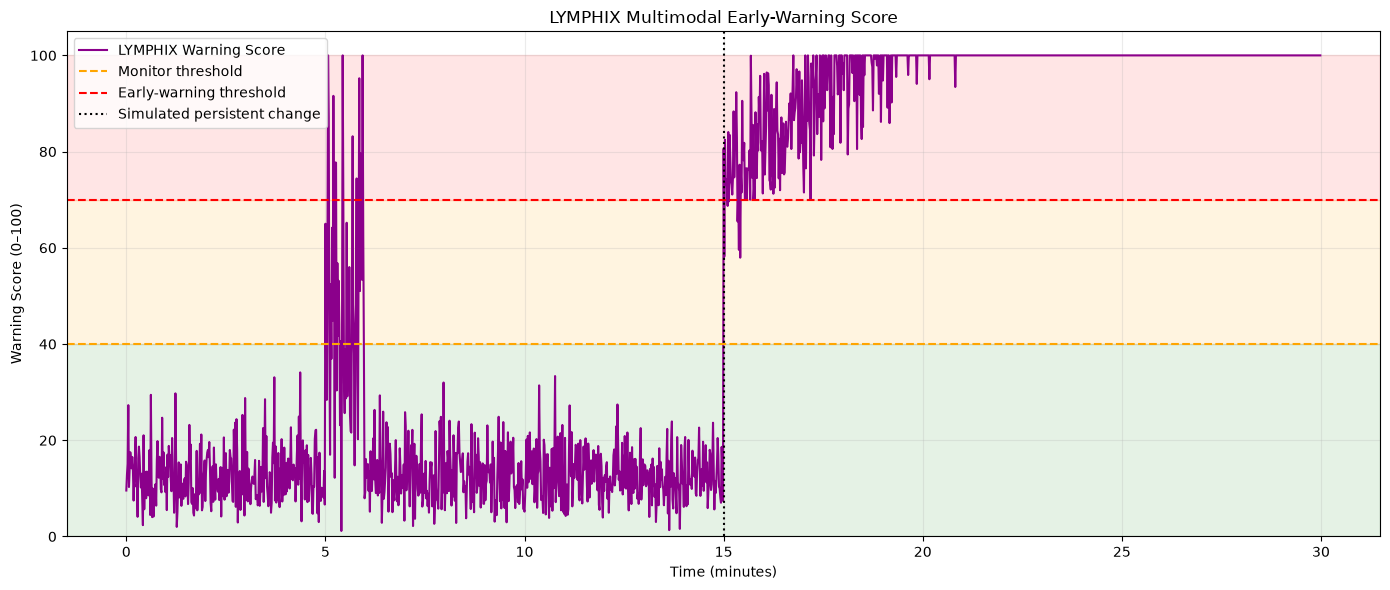

In [ ]:
# LYMPHIX FINAL MULTIMODAL WARNING GRAPH

plt.figure(figsize=(14, 6))

# Warning score
plt.plot(
    multi_df["time_s"] / 60,
    multi_df["warning_score"],
    color="darkmagenta",
    linewidth=1.5,
    label="LYMPHIX Warning Score"
)

# Normal zone
plt.axhspan(
    0,
    40,
    color="green",
    alpha=0.10
)

# Monitor zone
plt.axhspan(
    40,
    70,
    color="orange",
    alpha=0.12
)

# Early-warning zone
plt.axhspan(
    70,
    100,
    color="red",
    alpha=0.10
)

# Threshold lines
plt.axhline(
    40,
    color="orange",
    linestyle="--",
    linewidth=1.5,
    label="Monitor threshold"
)

plt.axhline(
    70,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Early-warning threshold"
)

# Persistent change begins at 15 minutes
plt.axvline(
    15,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Simulated persistent change"
)

plt.xlabel("Time (minutes)")
plt.ylabel("Warning Score (0–100)")

plt.title(
    "LYMPHIX Multimodal Early-Warning Score"
)

plt.ylim(0, 105)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()

plt.show()

In [ ]:
# SAVE COMPLETE LYMPHIX MULTIMODAL DATASET

final_file = (
    "../../data/loadcell/"
    "LYMPHIX_Multimodal_Processed.csv"
)

multi_df.to_csv(
    final_file,
    index=False
)

print("Complete LYMPHIX multimodal dataset saved.")
print(final_file)
print("Rows:", len(multi_df))
print("Columns:", len(multi_df.columns))

Complete LYMPHIX multimodal dataset saved.
../../data/loadcell/LYMPHIX_Multimodal_Processed.csv
Rows: 1800
Columns: 15


In [ ]:
# LYMPHIX DATASET STRUCTURE

print("LYMPHIX DATASET")
print("===============")

print("Rows:", len(multi_df))
print("Columns:", len(multi_df.columns))

print("\nColumn names:")

for i, column in enumerate(multi_df.columns, start=1):
    print(f"{i:02d}. {column}")

LYMPHIX DATASET
Rows: 1800
Columns: 15

Column names:
01. time_s
02. load_g
03. pressure
04. movement
05. load_z
06. pressure_z
07. movement_z
08. load_component
09. pressure_component
10. movement_component
11. fusion_score
12. warning_score
13. abnormal
14. persistent_change
15. final_status


In [ ]:
# LYMPHIX MISSING-VALUE CHECK

print("LYMPHIX MISSING-VALUE CHECK")
print("==========================")

missing_values = multi_df.isnull().sum()

print(missing_values)

print("\nTotal missing values:")
print(missing_values.sum())

LYMPHIX MISSING-VALUE CHECK
time_s                0
load_g                0
pressure              0
movement              0
load_z                0
pressure_z            0
movement_z            0
load_component        0
pressure_component    0
movement_component    0
fusion_score          0
warning_score         0
abnormal              0
persistent_change     0
final_status          0
dtype: int64

Total missing values:
0


In [ ]:
# LYMPHIX CLASS DISTRIBUTION

print("LYMPHIX CLASS DISTRIBUTION")
print("==========================")

class_counts = (
    multi_df["final_status"]
    .value_counts()
)

print("\nNumber of samples:")
print(class_counts)

class_percentages = (
    multi_df["final_status"]
    .value_counts(normalize=True)
    * 100
)

print("\nPercentage of samples:")
print(class_percentages.round(2))

LYMPHIX CLASS DISTRIBUTION

Number of samples:
final_status
NORMAL           873
EARLY_WARNING    871
MONITOR           56
Name: count, dtype: int64

Percentage of samples:
final_status
NORMAL           48.50
EARLY_WARNING    48.39
MONITOR           3.11
Name: proportion, dtype: float64


In [ ]:
# LYMPHIX MACHINE-LEARNING FEATURES

feature_columns = [
    "load_g",
    "pressure",
    "movement",
    "load_z",
    "pressure_z",
    "movement_z"
]

X = multi_df[feature_columns].copy()

y = multi_df["final_status"].copy()

print("LYMPHIX MACHINE-LEARNING DATA")
print("=============================")

print("Features used:")
print(feature_columns)

print()
print("X shape:", X.shape)
print("y shape:", y.shape)

print()
print("Target classes:")
print(y.value_counts())

LYMPHIX MACHINE-LEARNING DATA
Features used:
['load_g', 'pressure', 'movement', 'load_z', 'pressure_z', 'movement_z']

X shape: (1800, 6)
y shape: (1800,)

Target classes:
final_status
NORMAL           873
EARLY_WARNING    871
MONITOR           56
Name: count, dtype: int64


In [ ]:
# LYMPHIX TARGET CLASS ENCODING

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("LYMPHIX CLASS ENCODING")
print("======================")

print("Class mapping:")

for number, label in enumerate(label_encoder.classes_):
    print(number, "=", label)

print()
print("Encoded target shape:", y_encoded.shape)

LYMPHIX CLASS ENCODING
Class mapping:
0 = EARLY_WARNING
1 = MONITOR
2 = NORMAL

Encoded target shape: (1800,)


In [ ]:
# LYMPHIX TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("LYMPHIX TRAIN-TEST SPLIT")
print("========================")

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print()
print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

print()
print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print()
print("Testing class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

LYMPHIX TRAIN-TEST SPLIT
Training samples: 1440
Testing samples : 360

Training shape: (1440, 6)
Testing shape : (360, 6)

Training class distribution:
0    697
1     45
2    698
Name: count, dtype: int64

Testing class distribution:
0    174
1     11
2    175
Name: count, dtype: int64


In [ ]:
# LYMPHIX RANDOM FOREST MODEL

from sklearn.ensemble import RandomForestClassifier

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    max_depth=8,
    min_samples_leaf=3,
    n_jobs=-1
)

# Train the model
rf_model.fit(
    X_train,
    y_train
)

print("LYMPHIX RANDOM FOREST")
print("=====================")
print("Model training completed.")
print("Number of trees:", 200)
print("Maximum depth:", 8)
print("Class balancing: enabled")

LYMPHIX RANDOM FOREST
Model training completed.
Number of trees: 200
Maximum depth: 8
Class balancing: enabled


In [ ]:
# LYMPHIX MODEL PREDICTIONS

y_pred = rf_model.predict(X_test)

print("LYMPHIX PREDICTIONS")
print("===================")

print("Test samples:", len(y_test))
print("Predictions :", len(y_pred))

print()
print("First 20 predictions:")
print(y_pred[:20])

LYMPHIX PREDICTIONS
Test samples: 360
Predictions : 360

First 20 predictions:
[2 2 0 2 2 2 2 0 0 1 0 2 2 2 0 0 0 0 0 0]


In [ ]:
# LYMPHIX MODEL PERFORMANCE

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("LYMPHIX MODEL PERFORMANCE")
print("=========================")

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

LYMPHIX MODEL PERFORMANCE
Accuracy: 0.9444
Accuracy: 94.44%

Classification Report:
               precision    recall  f1-score   support

EARLY_WARNING       0.96      0.94      0.95       174
      MONITOR       0.26      0.45      0.33        11
       NORMAL       1.00      0.98      0.99       175

     accuracy                           0.94       360
    macro avg       0.74      0.79      0.76       360
 weighted avg       0.96      0.94      0.95       360



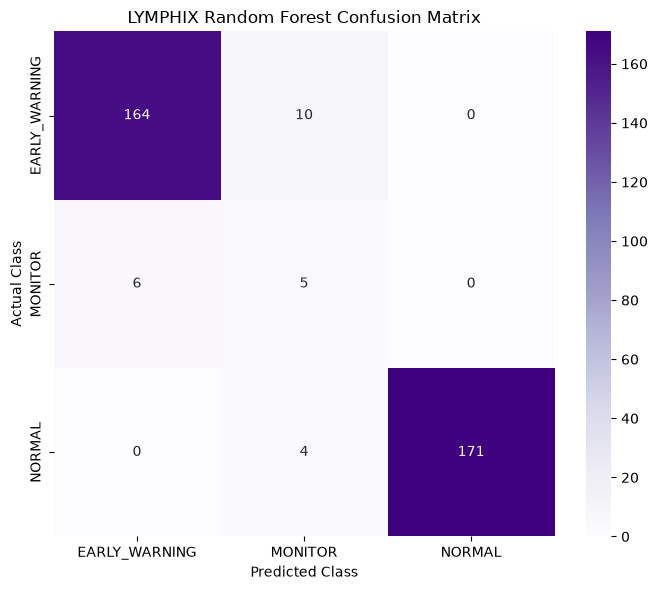

Confusion Matrix:
[[164  10   0]
 [  6   5   0]
 [  0   4 171]]


In [ ]:
# LYMPHIX CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "LYMPHIX Random Forest Confusion Matrix"
)

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

In [ ]:
# LYMPHIX TEMPORAL FEATURE ENGINEERING

temporal_df = multi_df.copy()

# Sort by time
temporal_df = temporal_df.sort_values(
    "time_s"
).reset_index(drop=True)

# 30-second rolling features
window = 30

temporal_df["load_mean_30s"] = (
    temporal_df["load_g"]
    .rolling(window)
    .mean()
)

temporal_df["pressure_mean_30s"] = (
    temporal_df["pressure"]
    .rolling(window)
    .mean()
)

temporal_df["movement_mean_30s"] = (
    temporal_df["movement"]
    .rolling(window)
    .mean()
)

temporal_df["load_std_30s"] = (
    temporal_df["load_g"]
    .rolling(window)
    .std()
)

temporal_df["pressure_std_30s"] = (
    temporal_df["pressure"]
    .rolling(window)
    .std()
)

temporal_df["movement_std_30s"] = (
    temporal_df["movement"]
    .rolling(window)
    .std()
)

# Rate of change
temporal_df["load_change"] = (
    temporal_df["load_g"].diff()
)

temporal_df["pressure_change"] = (
    temporal_df["pressure"].diff()
)

temporal_df["movement_change"] = (
    temporal_df["movement"].diff()
)

print("LYMPHIX TEMPORAL FEATURES CREATED")
print("=================================")

print("Total rows:", len(temporal_df))

print("\nNew features:")
print("30-second rolling means")
print("30-second rolling standard deviations")
print("Sensor rate-of-change features")

LYMPHIX TEMPORAL FEATURES CREATED
Total rows: 1800

New features:
30-second rolling means
30-second rolling standard deviations
Sensor rate-of-change features


In [ ]:
# LYMPHIX TEMPORAL FEATURE CHECK

temporal_features = [
    "load_mean_30s",
    "pressure_mean_30s",
    "movement_mean_30s",
    "load_std_30s",
    "pressure_std_30s",
    "movement_std_30s",
    "load_change",
    "pressure_change",
    "movement_change"
]

print("LYMPHIX TEMPORAL FEATURE CHECK")
print("==============================")

print("\nNumber of temporal features:",
      len(temporal_features))

print("\nMissing values:")
print(
    temporal_df[temporal_features]
    .isnull()
    .sum()
)

print("\nFirst 5 rows:")
print(
    temporal_df[
        temporal_features
    ].head()
)

LYMPHIX TEMPORAL FEATURE CHECK

Number of temporal features: 9

Missing values:
load_mean_30s        29
pressure_mean_30s    29
movement_mean_30s    29
load_std_30s         29
pressure_std_30s     29
movement_std_30s     29
load_change           1
pressure_change       1
movement_change       1
dtype: int64

First 5 rows:
   load_mean_30s  pressure_mean_30s  movement_mean_30s  load_std_30s  \
0            NaN                NaN                NaN           NaN   
1            NaN                NaN                NaN           NaN   
2            NaN                NaN                NaN           NaN   
3            NaN                NaN                NaN           NaN   
4            NaN                NaN                NaN           NaN   

   pressure_std_30s  movement_std_30s  load_change  pressure_change  \
0               NaN               NaN          NaN              NaN   
1               NaN               NaN    -1.904935         0.756094   
2               NaN           

In [ ]:
# LYMPHIX REMOVE INCOMPLETE TEMPORAL ROWS

temporal_df = temporal_df.dropna(
    subset=temporal_features
).reset_index(drop=True)

print("LYMPHIX TEMPORAL DATASET")
print("========================")

print("Rows remaining:", len(temporal_df))
print("Columns:", len(temporal_df.columns))

missing_total = (
    temporal_df[temporal_features]
    .isnull()
    .sum()
    .sum()
)

print(
    "Missing temporal values:",
    missing_total
)

LYMPHIX TEMPORAL DATASET
Rows remaining: 1771
Columns: 24
Missing temporal values: 0


In [ ]:
# LYMPHIX V2 MACHINE-LEARNING FEATURES

v2_features = [
    "load_g",
    "pressure",
    "movement",
    "load_z",
    "pressure_z",
    "movement_z",
    "load_mean_30s",
    "pressure_mean_30s",
    "movement_mean_30s",
    "load_std_30s",
    "pressure_std_30s",
    "movement_std_30s",
    "load_change",
    "pressure_change",
    "movement_change"
]

X_v2 = temporal_df[v2_features].copy()

y_v2 = temporal_df["final_status"].copy()

print("LYMPHIX V2 MACHINE-LEARNING DATA")
print("================================")

print("Number of features:", len(v2_features))
print("X_v2 shape:", X_v2.shape)
print("y_v2 shape:", y_v2.shape)

print("\nFeatures:")
print(v2_features)

print("\nTarget distribution:")
print(y_v2.value_counts())

LYMPHIX V2 MACHINE-LEARNING DATA
Number of features: 15
X_v2 shape: (1771, 15)
y_v2 shape: (1771,)

Features:
['load_g', 'pressure', 'movement', 'load_z', 'pressure_z', 'movement_z', 'load_mean_30s', 'pressure_mean_30s', 'movement_mean_30s', 'load_std_30s', 'pressure_std_30s', 'movement_std_30s', 'load_change', 'pressure_change', 'movement_change']

Target distribution:
final_status
EARLY_WARNING    871
NORMAL           844
MONITOR           56
Name: count, dtype: int64


In [ ]:
# LYMPHIX V2 TARGET ENCODING

from sklearn.preprocessing import LabelEncoder

label_encoder_v2 = LabelEncoder()

y_v2_encoded = label_encoder_v2.fit_transform(
    y_v2
)

print("LYMPHIX V2 CLASS ENCODING")
print("=========================")

print("Class mapping:")

for number, label in enumerate(
    label_encoder_v2.classes_
):
    print(number, "=", label)

print()
print(
    "Encoded target shape:",
    y_v2_encoded.shape
)

LYMPHIX V2 CLASS ENCODING
Class mapping:
0 = EARLY_WARNING
1 = MONITOR
2 = NORMAL

Encoded target shape: (1771,)


In [ ]:
# LYMPHIX V2 TRAIN-TEST SPLIT

from sklearn.model_selection import train_test_split

X_v2_train, X_v2_test, y_v2_train, y_v2_test = train_test_split(
    X_v2,
    y_v2_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_v2_encoded
)

print("LYMPHIX V2 TRAIN-TEST SPLIT")
print("===========================")

print("Training samples:", len(X_v2_train))
print("Testing samples :", len(X_v2_test))

print()
print("Training shape:", X_v2_train.shape)
print("Testing shape :", X_v2_test.shape)

print()
print("Training class distribution:")
print(
    pd.Series(y_v2_train)
    .value_counts()
    .sort_index()
)

print()
print("Testing class distribution:")
print(
    pd.Series(y_v2_test)
    .value_counts()
    .sort_index()
)

LYMPHIX V2 TRAIN-TEST SPLIT
Training samples: 1416
Testing samples : 355

Training shape: (1416, 15)
Testing shape : (355, 15)

Training class distribution:
0    696
1     45
2    675
Name: count, dtype: int64

Testing class distribution:
0    175
1     11
2    169
Name: count, dtype: int64


In [ ]:
# LYMPHIX RANDOM FOREST V2

from sklearn.ensemble import RandomForestClassifier

rf_model_v2 = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    max_depth=10,
    min_samples_leaf=3,
    n_jobs=-1
)

rf_model_v2.fit(
    X_v2_train,
    y_v2_train
)

print("LYMPHIX RANDOM FOREST V2")
print("========================")

print("Model training completed.")
print("Number of trees:", 300)
print("Maximum depth:", 10)
print("Class balancing: enabled")
print("Features:", X_v2_train.shape[1])

LYMPHIX RANDOM FOREST V2
Model training completed.
Number of trees: 300
Maximum depth: 10
Class balancing: enabled
Features: 15


In [ ]:
# LYMPHIX V2 PREDICTIONS

y_v2_pred = rf_model_v2.predict(
    X_v2_test
)

print("LYMPHIX V2 PREDICTIONS")
print("======================")

print("Test samples:", len(y_v2_test))
print("Predictions :", len(y_v2_pred))

print()
print("First 20 predictions:")
print(y_v2_pred[:20])

LYMPHIX V2 PREDICTIONS
Test samples: 355
Predictions : 355

First 20 predictions:
[0 2 0 1 2 0 2 0 2 2 2 0 2 1 2 2 0 2 2 0]


In [ ]:
# LYMPHIX V2 MODEL PERFORMANCE

from sklearn.metrics import (
    accuracy_score,
    classification_report
)

v2_accuracy = accuracy_score(
    y_v2_test,
    y_v2_pred
)

print("LYMPHIX V2 MODEL PERFORMANCE")
print("============================")

print(f"Accuracy: {v2_accuracy:.4f}")
print(f"Accuracy: {v2_accuracy * 100:.2f}%")

print("\nClassification Report:")

print(
    classification_report(
        y_v2_test,
        y_v2_pred,
        target_names=label_encoder_v2.classes_,
        zero_division=0
    )
)

LYMPHIX V2 MODEL PERFORMANCE
Accuracy: 0.9775
Accuracy: 97.75%

Classification Report:
               precision    recall  f1-score   support

EARLY_WARNING       1.00      1.00      1.00       175
      MONITOR       0.58      1.00      0.73        11
       NORMAL       1.00      0.95      0.98       169

     accuracy                           0.98       355
    macro avg       0.86      0.98      0.90       355
 weighted avg       0.99      0.98      0.98       355



In [ ]:
LYMPHIX V2 MODEL PERFORMANCE
============================
Accuracy: 0.9775
Accuracy: 97.75%

Classification Report:
               precision    recall  f1-score   support

EARLY_WARNING       1.00      1.00      1.00       175
      MONITOR       0.58      1.00      0.73        11
       NORMAL       1.00      0.95      0.98       169

     accuracy                           0.98       355
    macro avg       0.86      0.98      0.90       355
 weighted avg       0.99      0.98      0.98       355


IndentationError: unindent does not match any outer indentation level (<string>, line 13)

In [ ]:
# LYMPHIX V2 MODEL PERFORMANCE

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

v2_accuracy = accuracy_score(y_v2_test, y_v2_pred)

print("LYMPHIX V2 MODEL PERFORMANCE")
print("============================")

print("Accuracy:", round(v2_accuracy, 4))
print("Accuracy percentage:", round(v2_accuracy * 100, 2), "%")

print()
print("Classification Report:")

report = classification_report(
    y_v2_test,
    y_v2_pred,
    target_names=label_encoder_v2.classes_,
    zero_division=0
)

print(report)

LYMPHIX V2 MODEL PERFORMANCE
Accuracy: 0.9775
Accuracy percentage: 97.75 %

Classification Report:
               precision    recall  f1-score   support

EARLY_WARNING       1.00      1.00      1.00       175
      MONITOR       0.58      1.00      0.73        11
       NORMAL       1.00      0.95      0.98       169

     accuracy                           0.98       355
    macro avg       0.86      0.98      0.90       355
 weighted avg       0.99      0.98      0.98       355



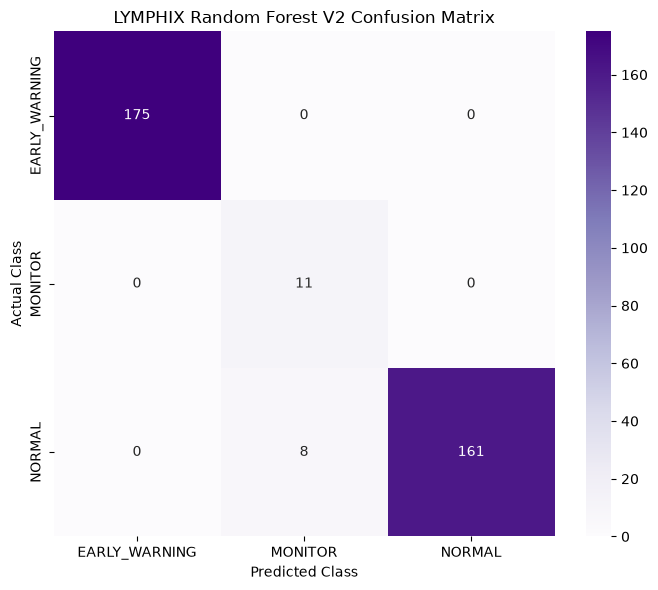

LYMPHIX V2 Confusion Matrix:
[[175   0   0]
 [  0  11   0]
 [  0   8 161]]


In [ ]:

# LYMPHIX V2 CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_v2 = confusion_matrix(
    y_v2_test,
    y_v2_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=label_encoder_v2.classes_,
    yticklabels=label_encoder_v2.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title(
    "LYMPHIX Random Forest V2 Confusion Matrix"
)

plt.tight_layout()
plt.show()

print("LYMPHIX V2 Confusion Matrix:")
print(cm_v2)

LYMPHIX V2 CONFUSION MATRIX
[[175   0   0]
 [  0  11   0]
 [  0   8 161]]


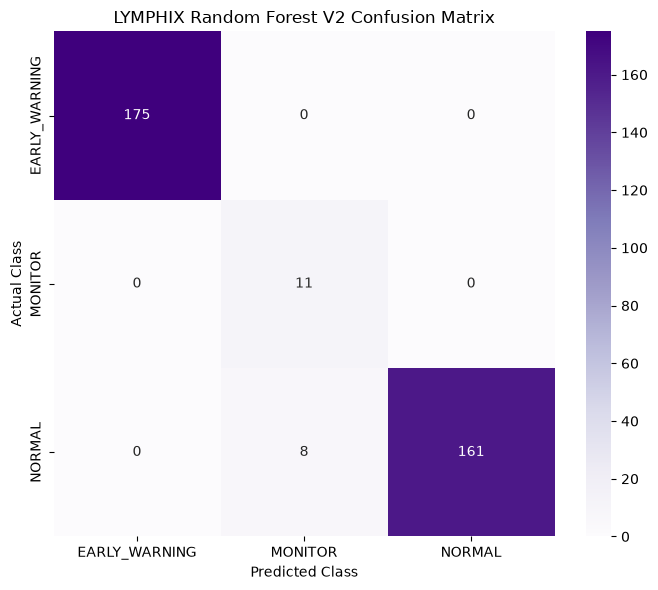

In [ ]:
# LYMPHIX V2 CONFUSION MATRIX

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_v2 = confusion_matrix(
    y_v2_test,
    y_v2_pred
)

print("LYMPHIX V2 CONFUSION MATRIX")
print("===========================")
print(cm_v2)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_v2,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=label_encoder_v2.classes_,
    yticklabels=label_encoder_v2.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("LYMPHIX Random Forest V2 Confusion Matrix")

plt.tight_layout()
plt.show()

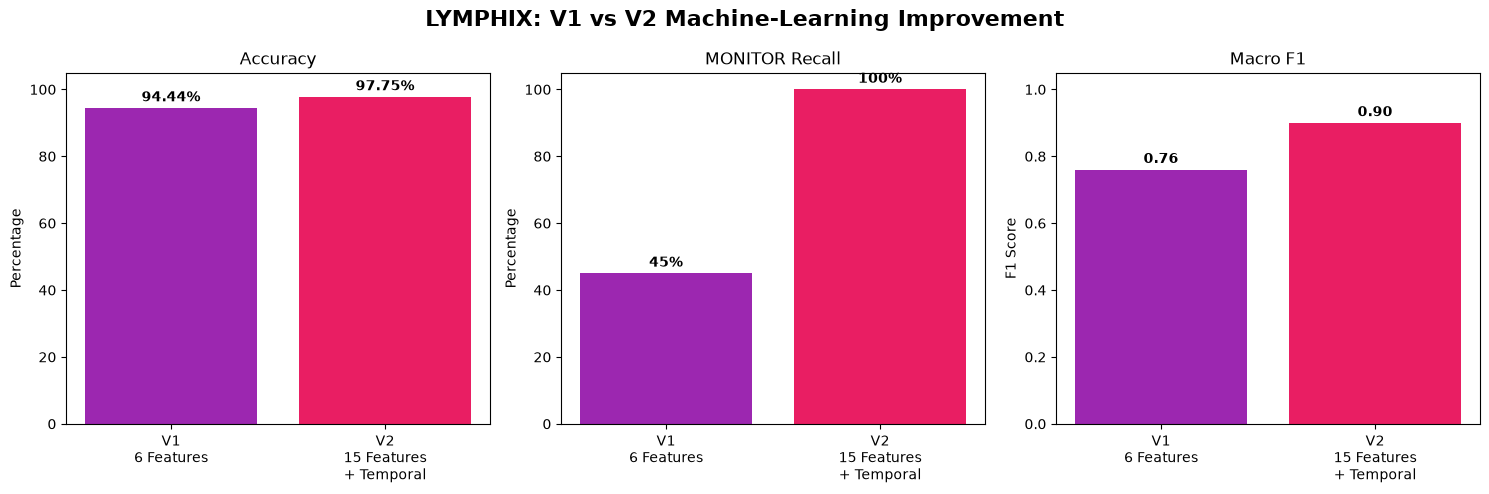

In [ ]:
# LYMPHIX V1 vs V2 COMPARISON

import matplotlib.pyplot as plt

models = [
    "V1\n6 Features",
    "V2\n15 Features\n+ Temporal"
]

accuracy_values = [
    94.44,
    97.75
]

monitor_recall = [
    45.00,
    100.00
]

macro_f1 = [
    0.76,
    0.90
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

# Accuracy
axes[0].bar(
    models,
    accuracy_values,
    color=["#9C27B0", "#E91E63"]
)

axes[0].set_title("Accuracy")
axes[0].set_ylabel("Percentage")
axes[0].set_ylim(0, 105)

for i, value in enumerate(accuracy_values):
    axes[0].text(
        i,
        value + 2,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

# MONITOR recall
axes[1].bar(
    models,
    monitor_recall,
    color=["#9C27B0", "#E91E63"]
)

axes[1].set_title("MONITOR Recall")
axes[1].set_ylabel("Percentage")
axes[1].set_ylim(0, 105)

for i, value in enumerate(monitor_recall):
    axes[1].text(
        i,
        value + 2,
        f"{value:.0f}%",
        ha="center",
        fontweight="bold"
    )

# Macro F1
axes[2].bar(
    models,
    macro_f1,
    color=["#9C27B0", "#E91E63"]
)

axes[2].set_title("Macro F1")
axes[2].set_ylabel("F1 Score")
axes[2].set_ylim(0, 1.05)

for i, value in enumerate(macro_f1):
    axes[2].text(
        i,
        value + 0.02,
        f"{value:.2f}",
        ha="center",
        fontweight="bold"
    )

plt.suptitle(
    "LYMPHIX: V1 vs V2 Machine-Learning Improvement",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

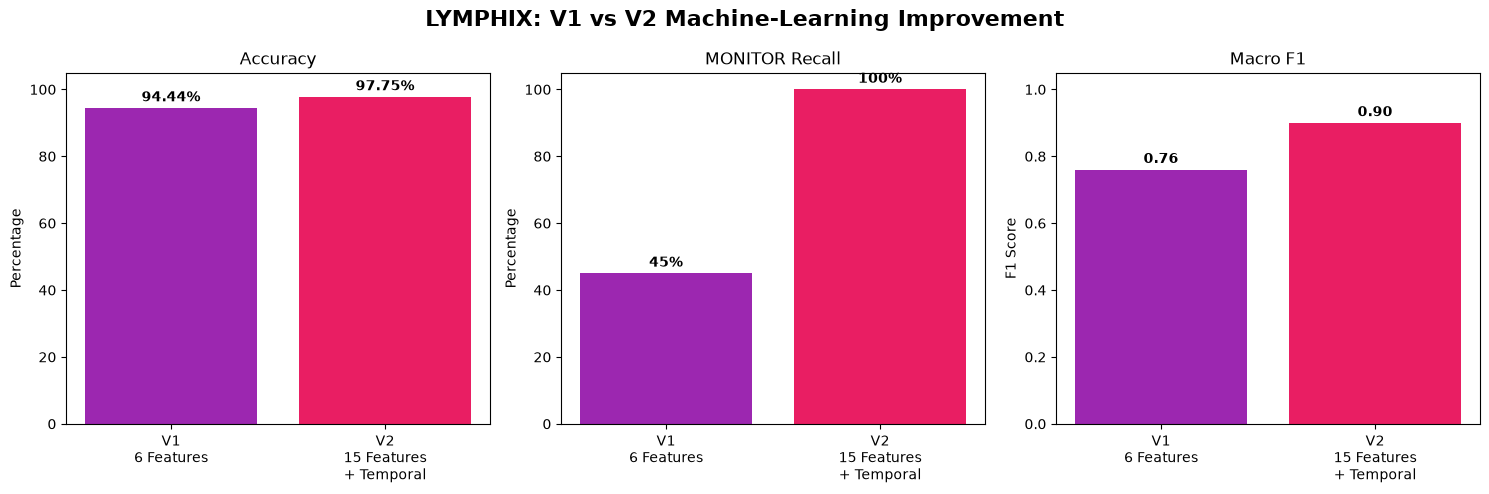

In [ ]:
# LYMPHIX V1 vs V2 COMPARISON

import matplotlib.pyplot as plt

models = [
    "V1\n6 Features",
    "V2\n15 Features\n+ Temporal"
]

accuracy_values = [94.44, 97.75]
monitor_recall = [45.00, 100.00]
macro_f1 = [0.76, 0.90]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Accuracy
axes[0].bar(
    models,
    accuracy_values,
    color=["#9C27B0", "#E91E63"]
)

axes[0].set_title("Accuracy")
axes[0].set_ylabel("Percentage")
axes[0].set_ylim(0, 105)

for i, value in enumerate(accuracy_values):
    axes[0].text(
        i,
        value + 2,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

# MONITOR recall
axes[1].bar(
    models,
    monitor_recall,
    color=["#9C27B0", "#E91E63"]
)

axes[1].set_title("MONITOR Recall")
axes[1].set_ylabel("Percentage")
axes[1].set_ylim(0, 105)

for i, value in enumerate(monitor_recall):
    axes[1].text(
        i,
        value + 2,
        f"{value:.0f}%",
        ha="center",
        fontweight="bold"
    )

# Macro F1
axes[2].bar(
    models,
    macro_f1,
    color=["#9C27B0", "#E91E63"]
)

axes[2].set_title("Macro F1")
axes[2].set_ylabel("F1 Score")
axes[2].set_ylim(0, 1.05)

for i, value in enumerate(macro_f1):
    axes[2].text(
        i,
        value + 0.02,
        f"{value:.2f}",
        ha="center",
        fontweight="bold"
    )

plt.suptitle(
    "LYMPHIX: V1 vs V2 Machine-Learning Improvement",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

LYMPHIX V2 FEATURE IMPORTANCE
              feature  importance
9        load_std_30s    0.155967
6       load_mean_30s    0.147145
7   pressure_mean_30s    0.122335
8   movement_mean_30s    0.114936
10   pressure_std_30s    0.098938
11   movement_std_30s    0.081043
0              load_g    0.066929
3              load_z    0.061810
4          pressure_z    0.055821
1            pressure    0.040772
2            movement    0.021166
5          movement_z    0.012978
12        load_change    0.011331
13    pressure_change    0.007332
14    movement_change    0.001495


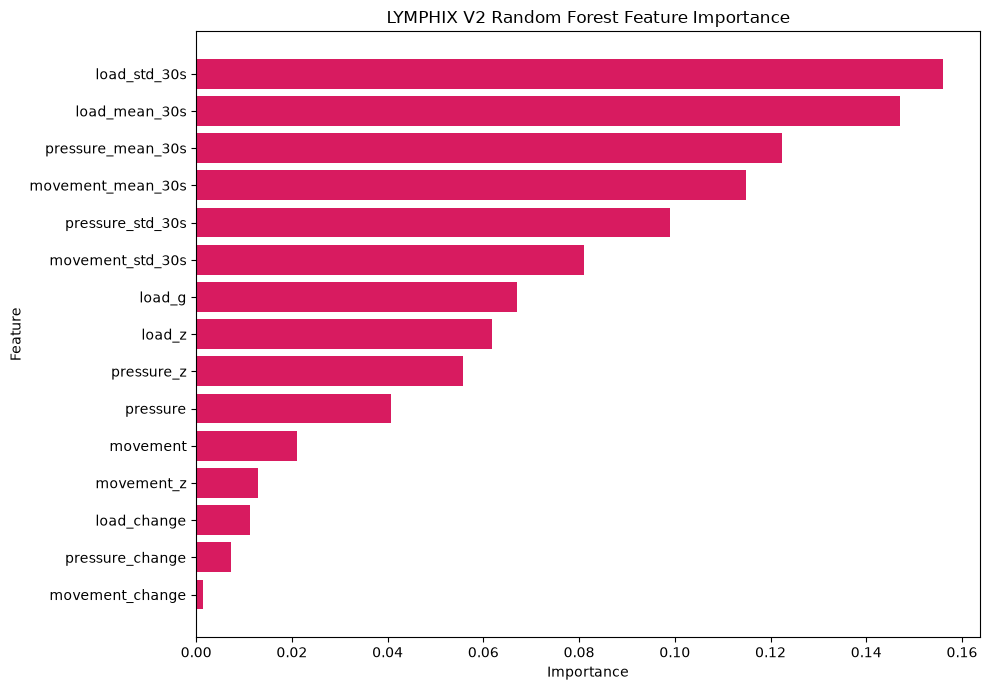

In [ ]:
# LYMPHIX V2 FEATURE IMPORTANCE

import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "feature": v2_features,
    "importance": rf_model_v2.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

print("LYMPHIX V2 FEATURE IMPORTANCE")
print("=============================")
print(importance_df)

plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["feature"],
    importance_df["importance"],
    color="#D81B60"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "LYMPHIX V2 Random Forest Feature Importance"
)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
# LYMPHIX SAVE V2 MODEL

import joblib

model_path = "../../models/LYMPHIX_RandomForest_V2.pkl"

joblib.dump(
    rf_model_v2,
    model_path
)

joblib.dump(
    label_encoder_v2,
    "../../models/LYMPHIX_LabelEncoder_V2.pkl"
)

joblib.dump(
    v2_features,
    "../../models/LYMPHIX_Features_V2.pkl"
)

print("LYMPHIX V2 MODEL SAVED")
print("======================")

print("Model:")
print(model_path)

print("Label encoder:")
print("../../models/LYMPHIX_LabelEncoder_V2.pkl")

print("Feature list:")
print("../../models/LYMPHIX_Features_V2.pkl")

FileNotFoundError: [Errno 2] No such file or directory: '../../models/LYMPHIX_RandomForest_V2.pkl'

In [ ]:
# LYMPHIX SAVE V2 MODEL

import joblib

model_path = "../../models/LYMPHIX_RandomForest_V2.pkl"

joblib.dump(
    rf_model_v2,
    model_path
)

joblib.dump(
    label_encoder_v2,
    "../../models/LYMPHIX_LabelEncoder_V2.pkl"
)

joblib.dump(
    v2_features,
    "../../models/LYMPHIX_Features_V2.pkl"
)

print("LYMPHIX V2 MODEL SAVED")
print("======================")

print("Model saved successfully:")
print(model_path)

print("Label encoder saved successfully.")

print("Feature list saved successfully.")

LYMPHIX V2 MODEL SAVED
Model saved successfully:
../../models/LYMPHIX_RandomForest_V2.pkl
Label encoder saved successfully.
Feature list saved successfully.


In [ ]:
# LYMPHIX MODEL VERIFICATION

import joblib

loaded_model = joblib.load(
    "../../models/LYMPHIX_RandomForest_V2.pkl"
)

loaded_encoder = joblib.load(
    "../../models/LYMPHIX_LabelEncoder_V2.pkl"
)

loaded_features = joblib.load(
    "../../models/LYMPHIX_Features_V2.pkl"
)

print("LYMPHIX MODEL VERIFICATION")
print("==========================")

print("Model loaded:", type(loaded_model).__name__)

print(
    "Number of trees:",
    loaded_model.n_estimators
)

print(
    "Number of features:",
    len(loaded_features)
)

print()
print("Classes:")
print(loaded_encoder.classes_)

print()
print("Features:")
print(loaded_features)

LYMPHIX MODEL VERIFICATION
Model loaded: RandomForestClassifier
Number of trees: 300
Number of features: 15

Classes:
['EARLY_WARNING' 'MONITOR' 'NORMAL']

Features:
['load_g', 'pressure', 'movement', 'load_z', 'pressure_z', 'movement_z', 'load_mean_30s', 'pressure_mean_30s', 'movement_mean_30s', 'load_std_30s', 'pressure_std_30s', 'movement_std_30s', 'load_change', 'pressure_change', 'movement_change']
